# Quick checks before training (no training, ~20-30 min on one GPU)

**Check 1, pure noise (H3):** add random noise to the weights of a checkpoint (no retraining) and measure self vs task change. If the self still "changes less" under pure noise, part of our gap comes from how we measure, not from learning. Also gives the noise-size -> movement curve used to size the Q2 push.

**Check 2, far-apart checkpoints:** Hindi only, phase p vs p+k. Does natural drift reach the continual level of movement (~45-50% task change), and is the self still protected there? Plus continual same-language pairs and ordinary switches as the reference.

Fixed tau = 0.2, MLP layers, FLORES dev inputs, phases <= 60. Outputs: `analysis/v6/quick_checks/`.

In [1]:
import os, sys, glob
REPO = "/workspace/shreshth"          # <- your repo folder on the instance
os.chdir(REPO); print(os.getcwd())
GPU = "0"

/workspace/shreshth


In [2]:
# 1. checkpoints (names like p030_ar.pt); downloads only missing ones
import shutil, glob
from huggingface_hub import HfApi, hf_hub_download
api = HfApi(); u = api.whoami()["name"]; REPO_ID = f"{u}/cml-lang-self-checkpoints"
files = api.list_repo_files(REPO_ID, repo_type="model")
print("check:", [f for f in files if f.startswith("v4b_continual_s0/ckpt/p03")][:4])

need = {"v4b_continual_s0": [30, 33, 44, 45, 46, 47, 59, 60],
        "v4b_only_hi_s0":   [2, 10, 30, 31, 35, 40, 45, 50, 60]}
for run, phases in need.items():
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        hits = [f for f in files if f.startswith(f"{run}/ckpt/p{ph:03d}_") and f.endswith(".pt")]
        if not hits:
            print("NOT IN REPO:", run, ph); continue
        print("downloading", hits[0], flush=True)
        path = hf_hub_download(REPO_ID, hits[0], repo_type="model")
        local = os.path.join("runs", hits[0])
        os.makedirs(os.path.dirname(local), exist_ok=True)
        shutil.copy(path, local)
print("checkpoints ok:", all(glob.glob(f"runs/{r}/ckpt/p{p:03d}_*.pt") for r, ps in need.items() for p in ps))

check: ['v4b_continual_s0/ckpt/p030_ar.pt', 'v4b_continual_s0/ckpt/p031_hi.pt', 'v4b_continual_s0/ckpt/p032_zh.pt', 'v4b_continual_s0/ckpt/p033_ar.pt']
checkpoints ok: True


In [3]:
# 2. FLORES dev files (en, hi, zh, ar). Skips if already there.
import json
codes = {"en": "eng_Latn", "hi": "hin_Deva", "zh": "cmn_Hans", "ar": "arb_Arab"}
os.makedirs("data/flores", exist_ok=True)
missing = [l for l in codes if not os.path.exists(f"data/flores/dev.{l}.jsonl")]
if missing:
    from datasets import load_dataset          # gated dataset: accept the terms on HF once, and be logged in
    for l in missing:
        ds = load_dataset("openlanguagedata/flores_plus", codes[l], split="dev")
        with open(f"data/flores/dev.{l}.jsonl", "w", encoding="utf-8") as f:
            for t in ds["text"]:
                f.write(json.dumps({"text": t}, ensure_ascii=False) + "\n")
        print("wrote", l, len(ds))
print({l: sum(1 for _ in open(f"data/flores/dev.{l}.jsonl")) for l in codes})   # should be 997 each

{'en': 997, 'hi': 997, 'zh': 997, 'ar': 997}


In [4]:
# 3. run (prints a line per comparison as it goes; ~20-30 min)
import sys
!{sys.executable} -u quick_checks.py --gpu {GPU}

tau = 0.2 | MLP layers | inputs: FLORES dev | output -> /workspace/shreshth/analysis/v6/quick_checks

CHECK 1: pure noise on the weights, no retraining (does the measure favour the self by itself?)
  noise        continual p45 + noise 0.03         task   0.2  self   0.1  random   0.1  gap   0.0  rel  27.6%  self size   54%  loss +{'hi': 0.009, 'zh': 0.008, 'ar': 0.004}
  noise        continual p45 + noise 0.1          task   1.9  self   1.4  random   1.6  gap   0.5  rel  27.5%  self size   53%  loss +{'hi': 0.066, 'zh': 0.066, 'ar': 0.036}
  noise        continual p45 + noise 0.2          task   7.5  self   5.5  random   6.5  gap   2.0  rel  26.5%  self size   51%  loss +{'hi': 0.237, 'zh': 0.256, 'ar': 0.156}
  noise        continual p45 + noise 0.4          task  28.0  self  21.3  random  25.4  gap   6.6  rel  23.7%  self size   38%  loss +{'hi': 1.035, 'zh': 1.176, 'ar': 1.09}
  noise        continual p45 + noise 0.5          task  41.8  self  32.8  random  39.0  gap   9.1  rel  21.

      check                                label  task  self_ch  random   gap  self_size  stays  rel_gap_pct
      noise           continual p45 + noise 0.03  0.17     0.13    0.15  0.05       0.54   0.97        27.64
      noise            continual p45 + noise 0.1  1.92     1.40    1.63  0.53       0.53   0.93        27.45
      noise            continual p45 + noise 0.2  7.51     5.52    6.47  1.99       0.51   0.85        26.49
      noise            continual p45 + noise 0.4 27.98    21.33   25.37  6.64       0.38   0.61        23.75
      noise            continual p45 + noise 0.5 41.83    32.77   39.03  9.06       0.29   0.46        21.66
      noise            continual p45 + noise 0.6 55.94    45.25   53.75 10.69       0.18   0.28        19.11
      noise                only p45 + noise 0.03  0.23     0.18    0.21  0.05       0.47   0.98        21.39
      noise                 only p45 + noise 0.1  2.53     2.01    2.29  0.52       0.46   0.93        20.66
      noise        

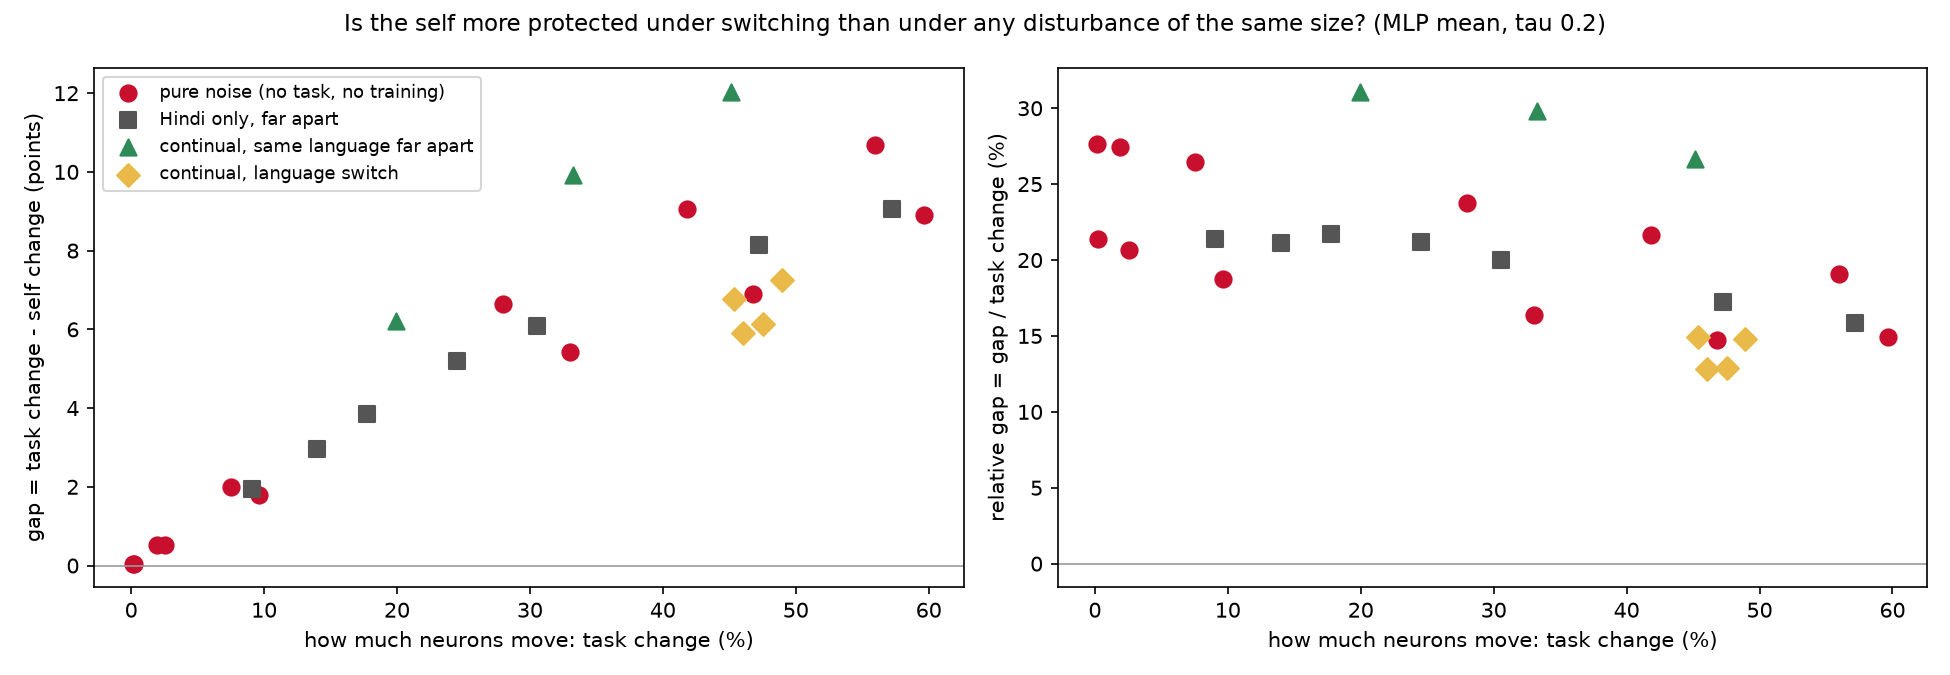

In [5]:
# 4. results
from IPython.display import Image, display
print(open("analysis/v6/quick_checks/summary.txt").read())
display(Image("analysis/v6/quick_checks/q2_movement_vs_gap.png"))